# Biweekly Report 2

## Candido Seneriches IV

### Large-Minibatch SGD and Gradual Warmup

#### Introduction
For this part of the report, I would like to build upon my previous investigation of Stochastic Gradient Descent (SGD) and focus on how it behaves when training convolutional neural networks. In particular, I will be experimenting with different minibatch sizes, learning rates, and a technique known as gradual warmup. 

Using the CIFAR-100 dataset, I want to see how changing these parameters affects training time, convergence and model accuracy. I will also be exploring the mathematical reasoning behind linear learning-rate scaling and whether these techniques can make training more efficient without signifcantly affecting performance. I will also take the time to also perform an Exploratory Data Analysis on CIFAR-100 as a stepup from CIFAR-10 which I went over in the other part of the report. With all of that said, let's get started.

To begin, let's go over briefly the underlying mathematics behind what this part of the report is doing. Suppose that the training dataset contains $N$ labeled examples. The objective that the model has is to minimize the average loss, defined as

$$
L(\theta) = \frac{1}{N}\sum_{i=1}^{N} \ell(x_i, y_i; \theta)
$$

for
- $\theta$ represents the trainable parameters of the CNN
- $(x_i, y_i)$ represents a training image and its label
- $\ell$ measures the prediction error for an individual example.

Rather than comptuing the gradient over the entire dataset for every update, minibatch SGD estimates it using a subset $\mathcal{B}_t$:

$$
\boxed{\theta_{t + 1} = \theta_t - \eta \frac{1}{B} \sum_{i \in \mathcal{B}_t} \nabla_{\theta}\ell(x_i), y_i; \theta_t}
$$

For $\eta$ is the learning rate, and $B = \left\lvert \mathcal{B}_t \right\rvert$ is the minibatch size. This minibatch size determines how many training examples contribute to each parameter update. For a dataset containing $N$ examples, the number of minibatches per epoch is:

$$
\boxed{S = \left\lceil \frac{N}{B} \right\rceil}
$$

If $B$ is increased, then the number of updates per epoch is reduced, but it also increases the amount of data processed during each update. This introduces a tradeoff between computational efficiency and optimization behavior, which I will investigate through this notebook.

When increasing the minibatch size, one approach is to scale the learning rate proportionally as

$$
\eta(B) = \eta_0 \frac{B}{B_0}
$$

For $B_0$ and $\eta_0$ are the reference minibatch size and learning rate. This is known as the **linear scaling rule**, movtivated by approximating several smaller SGD updates with one larger update, although the approximation is not always valid. To improve stability during the initial stages of training, we can also introduce *gradual warmup*, where the learning rate increases progressively toward its target value rather than starting at that value immediately. Both techniques will be investigated to determine whether or not they improve convergence when training with larger minibatches.

So now with the mathematics established, the questions now to answer are:
- How does minibatch size affect training efficiency?
- How does minibatch size affect the learning process?
- Can linear scaling and warmup improve large-minibatch training?

With all of that established, let's go ahead and officially start by loading up the data.

In [73]:
# General utilities
import os
import time
import math
import random
import shutil

# Numerical analysis and data visualization
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Dataset preparation
from torch.utils.data import Dataset, DataLoader, Subset
from torchvision import datasets, transforms
from PIL import Image
from torchvision.io import read_image, ImageReadMode


# Create a stratified training-validation split
from sklearn.model_selection import train_test_split

In [74]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"PyTorch Version: {torch.__version__}")
print(f"Device: {device}")

if device.type == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")
  print(f"Available GPUs: {torch.cuda.device_count()}")

  gpu_memory = torch.cuda.get_device_properties(0).total_memory
  print(f"GPU Memory: {gpu_memory / (1024 ** 3):.2f} GB")

else:
  print("CUDA unavailable. Running on CPU.")

PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
Available GPUs: 2
GPU Memory: 14.56 GB


 For the data, we'll be using the CIFAR-100 dataset, which is an extension of the CIFAR-10 dataset that I previously worked with. While both datasets contain 60,000 images with a resolution of $32 \times 32$ pixels, CIFAR-100 contains 100 classes compared to CIFAR-10's 10 classes, making image classification a more challenging task. Besides investigating the effects of minibatch size on SGD, I am also taking the time to explore how this increased number of classes affects the training process. All in all, this will allow me to build upon my previous work with CIFAR-10 while experimenting with a more complex classification problem. As reference, this dataset can be accessed on Kaggle [Here](https://www.kaggle.com/datasets/fedesoriano/cifar100)

In [75]:
from pathlib import Path
import pickle

DATA_DIR = Path("/kaggle/input/datasets/fedesoriano/cifar100")

# Dataset files
TRAIN_PATH = DATA_DIR / "train"
TEST_PATH = DATA_DIR / "test"
META_PATH = DATA_DIR / "meta"

# Load class metadata
with open(META_PATH, "rb") as f:
  metadata = pickle.load(f, encoding="bytes")

# Load fine and coarse class names
class_names = [
  name.decode("utf-8")
  for name in metadata[b"fine_label_names"]
]

coarse_class_names = [
  name.decode("utf-8")
  for name in metadata[b"coarse_label_names"]
]

# Map class identifiers to numerical labels
class_ids = list(range(len(class_names)))

class_to_idx = {
  class_name: idx
  for idx, class_name in enumerate(class_names)
}

# Verify dataset paths and metadata
required_paths = [
  TRAIN_PATH,
  TEST_PATH,
  META_PATH
]

paths_valid = all(path.is_file() for path in required_paths)
classes_valid = (
  len(class_ids) == len(class_to_idx) == len(class_names) == 100
  and len(coarse_class_names) == 20
)
labels_valid = all(name.strip() for name in class_names + coarse_class_names)

if paths_valid and classes_valid and labels_valid:
  print("CIFAR-100 setup: PASSED")
  print(f"Fine classes loaded: {len(class_names)}")
  print(f"Coarse classes loaded: {len(coarse_class_names)}")
  print("Training and test files: Ready")
  print("Class labels: Ready")
else:
  print("CIFAR-100 setup: FAILED")
  print("Missing files:", [str(path) for path in required_paths if not path.is_file()])
  print("Class metadata valid:", classes_valid and labels_valid)

CIFAR-100 setup: PASSED
Fine classes loaded: 100
Coarse classes loaded: 20
Training and test files: Ready
Class labels: Ready


#### CIFAR-100 EDA

Going a bit deeper into CIFAR-100, this dataset contains 100 image classes, with images having a resolution of $32 \times 32$ pixels. Compared to CIFAR-10, which contains only 10 classes, CIFAR-100 presents a more challenging classification problem despite having the same number of images. This EDA will focus on verifying the dataset, examining its class distribution, visualizing sample images, and investigating how different minibatch sizes affect the composition of training data. These observations will help establish the context for the experiments involving batch size, optimization, and computational efficiency.

In [76]:
# Load CIFAR-100 training data
with open(TRAIN_PATH, "rb") as f:
  train_data = pickle.load(f, encoding="bytes")

# Extract images and fine-class labels
all_images = train_data[b"data"].reshape(-1, 3, 32, 32)
all_images = all_images.transpose(0, 2, 3, 1)

all_labels = np.array(train_data[b"fine_labels"])

train_images, val_images, train_labels, val_labels = train_test_split(
  all_images,
  all_labels,
  test_size=0.2,
  random_state=SEED,
  stratify=all_labels
)

# Verify image counts and class coverage
print(f"Training images: {len(train_images):,}")
print(f"Validation images: {len(val_images):,}")
print(f"Classes represented: {len(np.unique(train_labels))}")
print(
  f"Training images per class: "
  f"{np.bincount(train_labels).min()}–{np.bincount(train_labels).max()}"
)

Training images: 40,000
Validation images: 10,000
Classes represented: 100
Training images per class: 400–400


In [77]:
# Inspect a sample of training images
rng = np.random.default_rng(SEED)

sample_indices = rng.choice(
  len(train_images),
  size=100,
  replace=False
)

sample_images = train_images[sample_indices]

print(f"Image dimensions: {set(image.shape[:2] for image in sample_images)}")
print(f"Image channels: {set(image.shape[2] for image in sample_images)}")
print(f"Image data type: {sample_images.dtype}")
print(f"Sample size: {len(sample_indices)}")

Image dimensions: {(32, 32)}
Image channels: {3}
Image data type: uint8
Sample size: 100


Here, the dataset already contains 100,000 training images and 10,000 validation images distributed across class. For each class, they contain 500 training images, confirming that the training dataset is balanced.

A random sample of 100 images also confirmed the expected $64 \times 64$ resolution. Both RGB and grayscale images were encounted, so all images will be converted to RGB during preprocessing to ensure consistent input dimensions for the CNN.

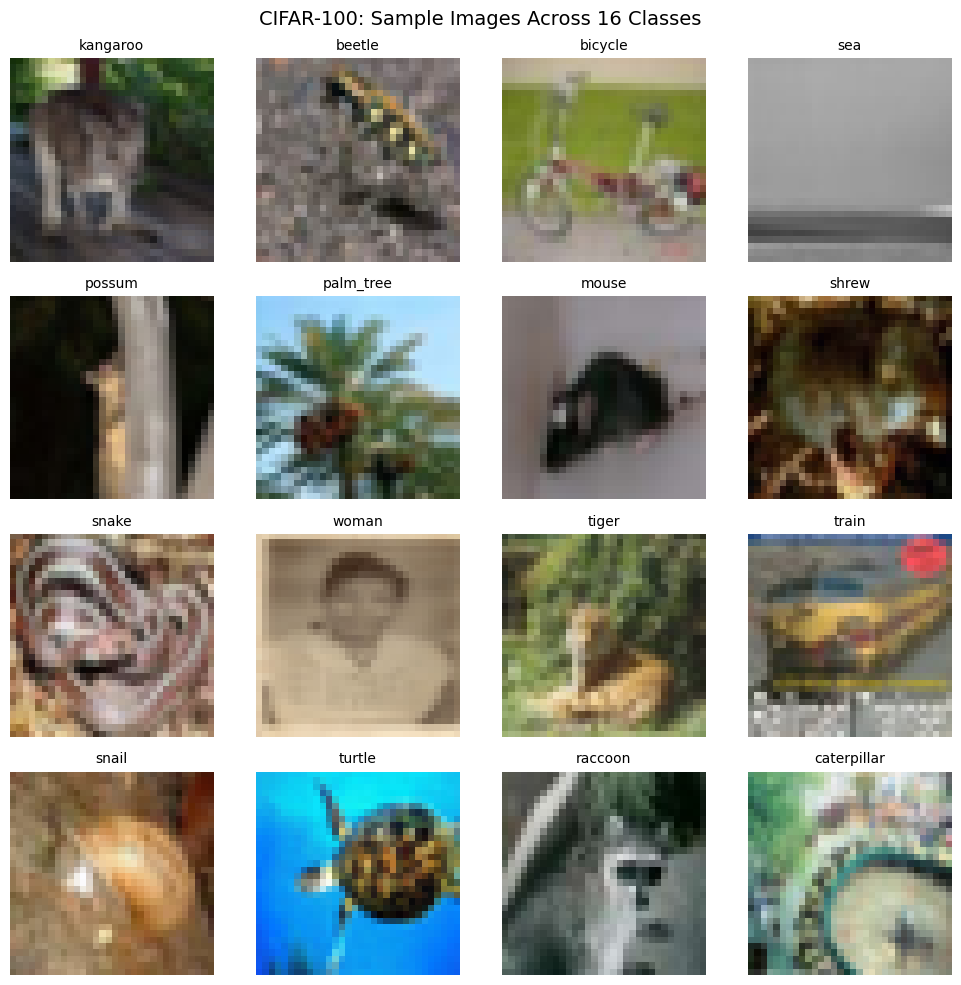

In [78]:
# Select 16 different classes
rng = np.random.default_rng(SEED)

selected_classes = rng.choice(len(class_ids), size=16, replace=False)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for ax, class_idx in zip(axes.flat, selected_classes):
  # Find images belonging to the selected class
  class_indices = np.where(train_labels == class_idx)[0]
  image_idx = rng.choice(class_indices)

  # Load and display the image
  image = train_images[image_idx]
  ax.imshow(image)

  ax.set_title(class_names[class_idx], fontsize=10)
  ax.axis("off")

plt.suptitle("CIFAR-100: Sample Images Across 16 Classes", fontsize=14)
plt.tight_layout()
plt.show()

Here in this picture gallery, we can see the diversity of objects represented in CIFAR-100, ranging from animals and vehicles to everyday objects. Images also vary in their backgrounds, object positions, and visual complexity.

Despite the relatively small image resolution of $32 \times 32$ pixels, the CNN must learn to distinguish among 100 classes, including categories that may share similar visual features. Compared to CIFAR-10, which contains only 10 classes, CIFAR-100 presents a more challenging classification task while maintaining the same image resolution and dataset size. Therefore, this provides a useful setting for investigating how different minibatch sizes affect SGD training, model performance, and computational efficiency.

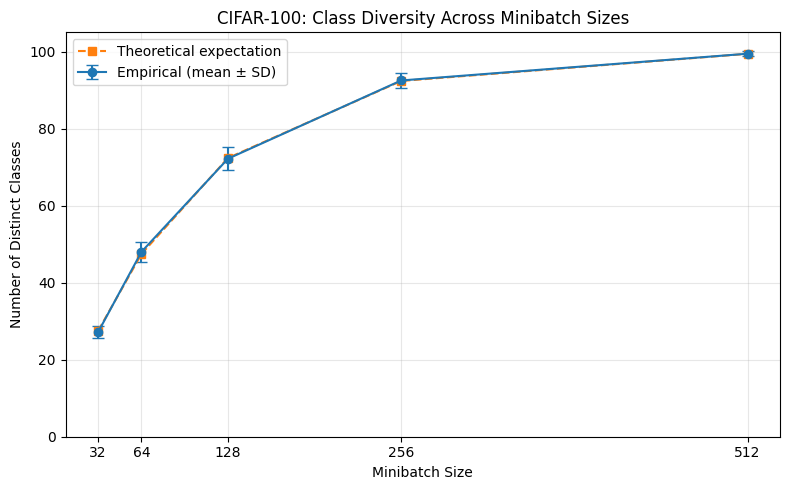

In [79]:
# Investigate class diversity across minibatch sizes
batch_sizes = [32, 64, 128, 256, 512]
num_trials = 100

rng = np.random.default_rng(SEED)

average_classes = []
std_classes = []

for batch_size in batch_sizes:
  distinct_counts = []

  for _ in range(num_trials):
    batch_labels = rng.choice(
      train_labels,
      size=batch_size,
      replace=False
    )

    distinct_counts.append(len(np.unique(batch_labels)))

  average_classes.append(np.mean(distinct_counts))
  std_classes.append(np.std(distinct_counts))

# Theoretical expectation under independent uniform sampling
expected_classes = [
  len(class_ids) * (1 - (1 - 1 / len(class_ids)) ** batch_size)
  for batch_size in batch_sizes
]

plt.figure(figsize=(8, 5))

plt.errorbar(
  batch_sizes,
  average_classes,
  yerr=std_classes,
  marker="o",
  capsize=4,
  label="Empirical (mean ± SD)"
)

plt.plot(
  batch_sizes,
  expected_classes,
  marker="s",
  linestyle="--",
  label="Theoretical expectation"
)

plt.title("CIFAR-100: Class Diversity Across Minibatch Sizes")
plt.xlabel("Minibatch Size")
plt.ylabel("Number of Distinct Classes")
plt.xticks(batch_sizes)
plt.ylim(0, 105)
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

The final thing to consider in this EDA is the minibatch composition. The following experiment examines how increasing minibatch size affects the number of distinct classes represented in a randomly sampled group of training images.

As minibatch size increases, more classes tend to appear within each batch, although the increase gradually slows because the dataset contains a fixed number of classes. The empirical results can also be compared with the theoretical expectation under uniform sampling. 

This provides an initial perspective on how minibatch size changes the composition of data used for each SGD update. However, class diversity alone doesn't determine the quality of the gradient estimate, so the effects on convergence and training efficiency will be investigated through the CNN experiments.

#### Setting up the CNN Architecture and Testing Environment
Moving onto the CNN itself, it will consist of three convolutional blocks, with each block applying a $3 \times 3$ convolution, batch normalization, ReLU activation, and max pooling. The number of feature channels increases from 32 to 64 and finally 126 as the spatial dimensions decrease.

After the convolutional blocks, global average pooling reduces the feature maps to a feature vector, which is passed into a fully connected layer producing 200 class scores.

The architecture will remain fixed throughout our experiments so that the differences in training performance can be attributed primarily to the minibatch size and learning-rate strategies rather than changes in network structure.

In [80]:
class CIFAR100CNN(nn.Module):
  def __init__(self):
    super().__init__()

    self.features = nn.Sequential(
      # Block 1: 3 x 32 x 32 -> 32 x 16 x 16
      nn.Conv2d(3, 32, kernel_size=3, padding=1),
      nn.BatchNorm2d(32),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 2: 32 x 16 x 16 -> 64 x 8 x 8
      nn.Conv2d(32, 64, kernel_size=3, padding=1),
      nn.BatchNorm2d(64),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2),

      # Block 3: 64 x 8 x 8 -> 128 x 4 x 4
      nn.Conv2d(64, 128, kernel_size=3, padding=1),
      nn.BatchNorm2d(128),
      nn.ReLU(),
      nn.MaxPool2d(kernel_size=2)
    )

    self.classifier = nn.Sequential(
      nn.AdaptiveAvgPool2d((1, 1)),
      nn.Flatten(),
      nn.Linear(128, 100)
    )

  def forward(self, x):
    x = self.features(x)
    x = self.classifier(x)
    return x

Mathematically, each convolutional block applies four operations: convolution, batch normalization, ReLU activation, and max pooling. Mathematically, this can be represented as

$$
X_{\ell+1}=\operatorname{MaxPool}\left(\operatorname{ReLU}\left(\operatorname{BN}\left(W_\ell*X_\ell+b_\ell\right)\right)\right)
$$

where $W_\ell*X_\ell$ represents convolution, $\operatorname{BN}$ normalizes the intermediate activations, ReLU introduces nonlinearity, and max pooling reduces the spatial dimensions while retaining prominent features.

After three convolutional blocks, global average pooling reduces the resulting feature maps into a vector of 128 features. The final fully connected layer computes

$$
z=W_{\mathrm{out}}h+b_{\mathrm{out}},\qquad z\in\mathbb{R}^{200}
$$

where $h\in\mathbb{R}^{128}$ is the extracted feature vector and $z$ contains the 200 class logits used for classification.

He initialization is applied to the convolutional and linear layers to help maintain stable activation magnitudes throughout the network. The architecture remains fixed across experiments to isolate the effects of minibatch size and learning-rate strategies.

In [81]:
# Initialize CNN weights
def initialize_model(model):
  for module in model.modules():
    if isinstance(module, (nn.Conv2d, nn.Linear)):
      nn.init.kaiming_normal_(
        module.weight,
        mode="fan_in",
        nonlinearity="relu"
      )

      if module.bias is not None:
        nn.init.zeros_(module.bias)

# Construct the model
torch.manual_seed(SEED)

model = CIFAR100CNN()
initialize_model(model)
model = model.to(device)

# Verify output dimensions
with torch.no_grad():
  sample_input = torch.randn(2, 3, 32, 32, device=device)
  sample_output = model(sample_input)

parameter_count = sum(
  p.numel() for p in model.parameters() if p.requires_grad
)

print(f"Device: {device}")
print(f"Input shape: {tuple(sample_input.shape)}")
print(f"Output shape: {tuple(sample_output.shape)}")
print(f"Trainable parameters: {parameter_count:,}")

Device: cuda
Input shape: (2, 3, 32, 32)
Output shape: (2, 100)
Trainable parameters: 106,596


Now that the CNN architecture is built and verified, let's prepare the images for training, and for the following experiments, the preprocessing of the data must be consistent across all minibatch experiments.

In terms of the images, the CNN expects input tensors of the shape

$$
(B, 3, 64, 64)
$$

For $B$ is the minibatch size. For this, three three transformations will be made:
- RGB Conversion
- Tensor conversion (Converting pixel intesities from integers to floating-point values)
- Normalization

In [82]:
from torchvision.transforms import functional as TF

image_transform = transforms.Compose([
  transforms.ToTensor(),
  transforms.Normalize(
    mean=[0.5071, 0.4867, 0.4408],
    std=[0.2675, 0.2565, 0.2761]
  )
])

In [83]:
class CIFAR100Dataset(Dataset):
  def __init__(self, images, labels, transform=None):
    self.images = images
    self.labels = labels
    self.transform = transform

  def __len__(self):
    return len(self.images)

  def __getitem__(self, idx):
    image = self.images[idx]
    label = int(self.labels[idx])

    if self.transform is not None:
      image = self.transform(image)

    return image, label


train_dataset = CIFAR100Dataset(
  train_images,
  train_labels,
  transform=image_transform
)

val_dataset = CIFAR100Dataset(
  val_images,
  val_labels,
  transform=image_transform
)

print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Training samples: 40,000
Validation samples: 10,000


Verify the dataset returns the correctly shaped tensors and numerical labels

In [84]:
sample_image, sample_label = train_dataset[0]

print(f"Image shape: {tuple(sample_image.shape)}")
print(f"Image dtype: {sample_image.dtype}")
print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

Image shape: (3, 32, 32)
Image dtype: torch.float32
Training samples: 40,000
Validation samples: 10,000


Now that the images have been preprocessed, I'll use PyTorch's `DataLoader` to organize them into minibatches for training and validation. A `DataLoader` helps group the images into batches, shuffle training examples, and load images efficiently.

For the experiments, the batch size $B$ will be configurable, allowing me to investigate its effect on training performance without changing the CNN architecture. With $N = 40,000$ training images, the number of minibatches per epoch is

$$
S(B) = \left\lceil \frac{N}{B} \right\rceil
$$

with each minibatch generally corresponding to one SGD parameter update. Although larger minibatches reduce the number of SGD updates per epoch, each update requires processing more training samples. Let $N$ denote the number of training images, $B$ the minibatch size, and $C$ the computational cost of processing one image through the CNN.

Since each epoch requires approximately $\frac{N}{B}$ updates, with reach update costing $O(BC)$, the overal training complexity is 

$$
T(N,B,E)=O\left(E\cdot\frac{N}{B}\cdot BC\right)=\boxed{O(ENC)}.
$$

Thus, for a fixed CNN architecture and number of epochs, the theoretical computational workload is approximately independent of minibatch size.

However actual training time depends of GPU parallelism, memory usage, and computational overhead. During the experiments, the runtime will be measured across different minibatch sizes to investigate how these theoretical expectations compare with empirical performance.

In [85]:
def create_dataloaders(batch_size, seed=42):
  generator = torch.Generator().manual_seed(seed)

  train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=(device.type == "cuda"),
    generator=generator
  )

  val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=(device.type == "cuda")
  )

  return train_loader, val_loader

To verify that this data loader function works, let's test it with a batch size of 128.

In [86]:
BATCH_SIZE = 128

train_loader, val_loader = create_dataloaders(BATCH_SIZE, seed=SEED)

images, labels = next(iter(train_loader))

print(f"Batch size: {BATCH_SIZE}")
print(f"Image batch shape: {tuple(images.shape)}")
print(f"Label batch shape: {tuple(labels.shape)}")
print(f"Training batches per epoch: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Batch size: 128
Image batch shape: (128, 3, 32, 32)
Label batch shape: (128,)
Training batches per epoch: 313
Validation batches: 79


In [87]:
images, labels = next(iter(create_dataloaders(128)[0]))

print("Image batch:", images.shape)
print("Image dtype:", images.dtype)
print("Label batch:", labels.shape)
print("Dataset path:", TRAIN_PATH)

Image batch: torch.Size([128, 3, 32, 32])
Image dtype: torch.float32
Label batch: torch.Size([128])
Dataset path: /kaggle/input/datasets/fedesoriano/cifar100/train


And finally, let's see how increasing batch size reduces the number of SGD updates per epoch.

In [88]:
# Compare minibatch sizes and SGD updates
batch_sizes = [32, 64, 128, 256, 512]

batch_summary = pd.DataFrame({
  "Batch Size": batch_sizes,
  "SGD Updates per Epoch": [
    (len(train_dataset) + B - 1) // B
    for B in batch_sizes
  ]
})

display(batch_summary)

,Batch Size,SGD Updates per Epoch
0,32,1250
1,64,625
2,128,313
3,256,157
4,512,79


Here, the table demonstrates the inverse relationship between minibatch size and the number of SGD updates performed per epoch. As the batch size increases, fewer updates are required to process the entire training dataset.

However, fewer updates do not necessarily translate into proportionally faster training, since larger minibatches require more computation per update. This motivates our upcoming experiments, where we will compare actual training times and model performance across different batch sizes.

The final part of setup is setting up two functions, one function will perform one complete training epoch, processing every minibatch and updating the CNN's parameters using SGD.

For each minitbatch $\mathcal{B}_t$, the optimizer applies

$$
w_{t + 1} = w_t - \eta_t \frac{1}{| \mathcal{B}_t |} \sum_{i \in \mathcal{B}_t} \nabla_{w}\ell_{i}(w_t)
$$

Where $\eta_t$ is the learning rate and $w_t$ represents the CNN's trainable parameters.

The other function will be a validation function, in which it will evaluate the CNN without modifying the parameters. For both functions, they'll return the same metrics:

$$
\text{Average Loss} = \frac{1}{N} \sum_{i = 1}{N} \ell_i
$$

$$
\text{Accuracy} = \frac{\text{Correct Predictions}}{N}
$$

In [89]:
def train_one_epoch(model, loader, optimizer, criterion, device):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  return total_loss / total, correct / total

def evaluate(model, loader, criterion, device):
  model.eval()

  total_loss = 0.0
  correct = 0
  total = 0

  with torch.inference_mode():
    for images, labels in loader:
      images = images.to(device, non_blocking=True)
      labels = labels.to(device, non_blocking=True)

      outputs = model(images)
      loss = criterion(outputs, labels)

      batch_size = labels.size(0)

      total_loss += loss.item() * batch_size
      correct += (outputs.argmax(dim=1) == labels).sum().item()
      total += batch_size

  return total_loss / total, correct / total

#### Experimental Analysis: Large-Minibatch SGD
With the dataset, CNN architecture, and training pipeline established, it is now time to investigate how minibatch size influences the optimization process. In stochastic gradient descent (SGD), the minibatch size determines how many training examples contribute to each gradient estimate. Mathematically, this means:

$$
\nabla L_{\mathcal B}(w)=\frac{1}{|\mathcal B|}\sum_{i\in\mathcal B}\nabla\ell_i(w).
$$

Increasing the minibatch generally produces a less noisy estimate of the full gradient, but also reduces the number of parameter updates per epoch and increases the computational work required for each update.

The experiments done will compare different minibatch sizes in terms of training loss, validation accuracy, and computational efficiency. We will also investigate whether learning-rate scaling and gradual warmup help maintain optimization performance when training with larger minibatches.

Before conducting these comparisons, let's perform a short test run that the training and validation functions operate correctly.

In [90]:
# Short training and validation sanity test

SANITY_BATCH_SIZE = 128
SANITY_TRAIN_SIZE = 1024
SANITY_VAL_SIZE = 256

torch.manual_seed(SEED)

sanity_train_dataset = Subset(
  train_dataset,
  torch.randperm(len(train_dataset))[:SANITY_TRAIN_SIZE].tolist()
)

sanity_val_dataset = Subset(
  val_dataset,
  torch.randperm(len(val_dataset))[:SANITY_VAL_SIZE].tolist()
)

sanity_train_loader = DataLoader(
  sanity_train_dataset,
  batch_size=SANITY_BATCH_SIZE,
  shuffle=True,
  num_workers=2,
  pin_memory=(device.type == "cuda")
)

sanity_val_loader = DataLoader(
  sanity_val_dataset,
  batch_size=SANITY_BATCH_SIZE,
  shuffle=False,
  num_workers=2,
  pin_memory=(device.type == "cuda")
)

sanity_model = CIFAR100CNN()
initialize_model(sanity_model)
sanity_model = sanity_model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
  sanity_model.parameters(),
  lr=0.01,
  momentum=0.9
)

train_loss, train_acc = train_one_epoch(
  sanity_model,
  sanity_train_loader,
  optimizer,
  criterion,
  device
)

val_loss, val_acc = evaluate(
  sanity_model,
  sanity_val_loader,
  criterion,
  device
)

print(f"Training Loss: {train_loss:.4f}")
print(f"Training Accuracy: {train_acc:.2%}")
print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_acc:.2%}")

Training Loss: 5.2108
Training Accuracy: 0.68%
Validation Loss: 5.1265
Validation Accuracy: 1.17%


With the training and validation functions verified, we can now construct a reusable framework for evaluating different minibatch sizes.

For each experiment, the CNN will be initialized with the same architecture and seed, while the minibatch size and learning-rate configuration can be adjusted. The training/validation losses, classification accuracy, epoch runtime, and image throughput will be recorded.

Training throughput is defined as

$$
R(B)=\frac{N}{T_{\text{train}}(B)},
$$

Where $N$ is the number of training images and $T_{\text{train}}(B)$ is the measured training time for one epoch.

The peak GPU memory allocation will also be recorded to investigate whether or not minibatch size affects memory requirements, and if so how big of an impact is it. These measurements will help evaluate optimization performance and computational efficiency.

In [91]:
def run_experiment(batch_size, learning_rate=0.01, epochs=3, seed=42):
  torch.manual_seed(seed)

  if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)

  train_loader, val_loader = create_dataloaders(batch_size, seed=seed)

  model = CIFAR100CNN()
  initialize_model(model)
  model = model.to(device)

  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=learning_rate,
    momentum=0.9
  )

  history = []

  for epoch in range(1, epochs + 1):
    if device.type == "cuda":
      torch.cuda.synchronize()
      torch.cuda.reset_peak_memory_stats(device)

    start = time.perf_counter()

    train_loss, train_acc = train_one_epoch(
      model, train_loader, optimizer, criterion, device
    )

    if device.type == "cuda":
      torch.cuda.synchronize()
      peak_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    else:
      peak_memory = None

    train_time = time.perf_counter() - start

    val_loss, val_acc = evaluate(
      model, val_loader, criterion, device
    )

    history.append({
      "Epoch": epoch,
      "Batch Size": batch_size,
      "Learning Rate": learning_rate,
      "Training Loss": train_loss,
      "Training Accuracy": train_acc,
      "Validation Loss": val_loss,
      "Validation Accuracy": val_acc,
      "Training Time (s)": train_time,
      "Throughput (images/s)": len(train_dataset) / train_time,
      "Peak GPU Memory (MiB)": peak_memory
    })

  return pd.DataFrame(history)

Before testing all five minibatch sizes, let's run one baseline configuration to show whether the CNN's training loss decreases over multiple epochs and will provide an initial estimate of the runtime for future experiments. Keep in mind that the sanity run only went for 1 epoch.

In [92]:
baseline_history = run_experiment(
  batch_size=128,
  learning_rate=0.01,
  epochs=3,
  seed=SEED
)

display(baseline_history.round(4))

,Epoch,Batch Size,Learning Rate,Training Loss,Training Accuracy,Validation Loss,Validation Accuracy,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,1,128,0.01,4.0593,0.0945,3.7596,0.1425,3.8010,10523.4220,108.624
1,2,128,0.01,3.5576,0.1695,3.4455,0.1841,3.6656,10912.2245,108.624
2,3,128,0.01,3.2841,0.2163,3.2657,0.2121,3.6420,10982.9068,108.624


Here, I trained the CIFAR-100 CNN using a minibatch size of 128, a learning rate of 0.01, and SGD with momentum for three epochs. The training accuracy increased from 9.40% to 21.61% while the validation accuracy increased from 14.24% to 21.26%. Both training and validation losses also decreased throughout the experiment, indicating that the CNN was successfully learning features from the dataset.

In terms of computational performance, each epoch took approximately 3.66 seconds to train, with a throughput of around 10,900 images per second. The peak allocated GPU memory remained approximately 108.6 MiB. These results establish a baseline that can be used to compare the effects of different minibatch sizes on training efficiency, memory usage, and model performance.

Although the classification accuracy is still relatively low, this is reasonable conisdering that CIFAR-100 contains 100 classes and the CNN was only trained for three epochs. The main objective is not to maximize classification accuracy, but rather to establish a consistent reference point for investigating large-minibatch SGD.


#### Experiment 1: Effect of Minibatch Size on SGD
With this benchmark, let's move onto the actual experimentation, where I'll train the model with varying minibatch sizes $(B = 32, 64, 128, 256, 512)$ and see how the sizes affect convergence and computational efficiency.

In [93]:
# Compare minibatch sizes with a fixed learning rate
batch_sizes = [32, 64, 128, 256, 512]

experiment_results = []

for batch_size in batch_sizes:
  print(f"Training with batch size {batch_size}...")

  if batch_size == 128:
    history = baseline_history.copy()
  else:
    history = run_experiment(
      batch_size=batch_size,
      learning_rate=0.01,
      epochs=3,
      seed=SEED
    )

  experiment_results.append(history)

comparison_history = pd.concat(
  experiment_results,
  ignore_index=True
)

print("Minibatch comparison completed.")

Training with batch size 32...
Training with batch size 64...
Training with batch size 128...
Training with batch size 256...
Training with batch size 512...
Minibatch comparison completed.


In [94]:
# Summarize final performance and computational efficiency
comparison_summary = (
  comparison_history
  .groupby("Batch Size")
  .agg({
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

comparison_summary["SGD Updates per Epoch"] = [
  (len(train_dataset) + B - 1) // B
  for B in comparison_summary["Batch Size"]
]

display(comparison_summary.round(4))

,Batch Size,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB),SGD Updates per Epoch
0,32,0.2659,0.2744,2.9561,2.9366,5.9391,6736.5014,42.9619,1250
1,64,0.2488,0.2503,3.0772,3.0661,3.9960,10010.1737,64.7241,625
2,128,0.2163,0.2121,3.2841,3.2657,3.7029,10806.1844,108.6240,313
3,256,0.1725,0.1838,3.5668,3.5084,2.9731,13472.9996,196.1738,157
4,512,0.1320,0.1403,3.8371,3.7942,2.6309,15217.4734,690.3442,79


Here after running the tests and increasing the minibatch size, we can observe a tradeoff between classification performance and computational efficiency as the minibatch size increases. Smaller minibatches generally achieved higher training and validation accuracy, with a batch size of 32 producing the highest accuracy of 27.40%. Meanwhile, the largest minibatch size of 512 acheived only 14.01% validation accuracy after three epochs.

This can be seen visually in figure A, as across the three epochs, all five minibatch sizes demonstrated improvements throughout training. However, smaller minibatches consistently achieved higher validation accuracy at every epoch, with a batch size of 32 performing the best and a batch size of 512 performing the worst. Furthermore, none of the curves appear to have completely leveled off by the third epoch, suggesting that additional training could lead to further improvements. Nevertheless, these results demonstrate how minibatch size can influence the rate at which the CNN learns under a fixed learning rate and number of epochs.

A possible explanation for this difference is the number of SGD updates performed during training. For example, a minibatch size of 32 requires 1,250 updates per epoch, while a minibatch size of 512 requires on 79 updates. Since all experiments used the same learning rate and number of epochs, smaller minibatches performed more parameter updates, which may have contributed to the stronger performance.

On the other hand, larger minibatches showcased better computational efficiency. Training time decreased from approximately 5.96 seconds per epoch at a batch size of 32 to 2.73 seconds at a batch size of 512. Similarly, throughput increased from approximately 5,714 to 14,679 images per second. However this improvement came at the cost of greater GPU memory consumption which increased substantially as the minibatch size grew.

And looking at figure B, we can see that increasing the minibatch size generally allows the CNN to process more images per second. For example, throughput increased from approximately 6,714 images per second at a batch size of 32 to 14,679 images per second at a batch size of 512, representing an improvement of approximately 2.19 times. However, the improvements become less significant at larger minibatch sizes. In particular, increasing the batch size from 256 to 512 only improved throughput by approximately 7.1%, suggesting diminishing returns in computational efficiency. This indicates that while larger minibatches can make better use of GPU parallelism, increasing the minibatch size does not necessarily result in proportional improvements in training speed.

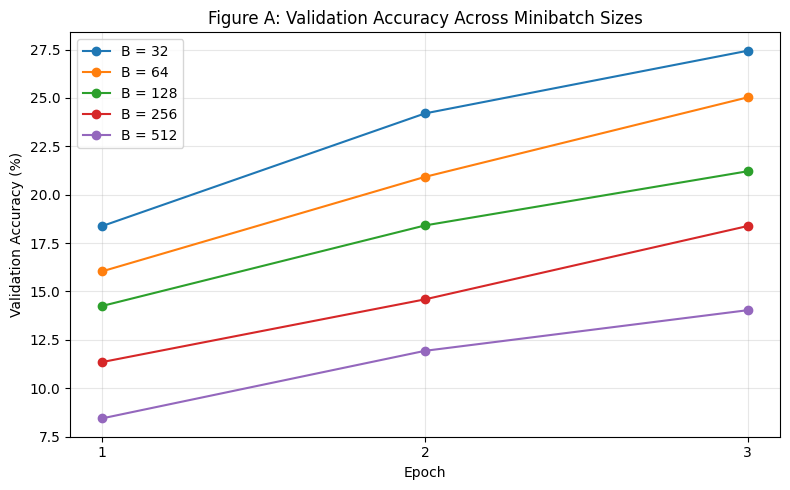

In [95]:
plt.figure(figsize=(8, 5))

for batch_size in batch_sizes:
  history = comparison_history[
    comparison_history["Batch Size"] == batch_size
  ]

  plt.plot(
    history["Epoch"],
    history["Validation Accuracy"] * 100,
    marker="o",
    label=f"B = {batch_size}"
  )

plt.title("Figure A: Validation Accuracy Across Minibatch Sizes")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.xticks([1, 2, 3])
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

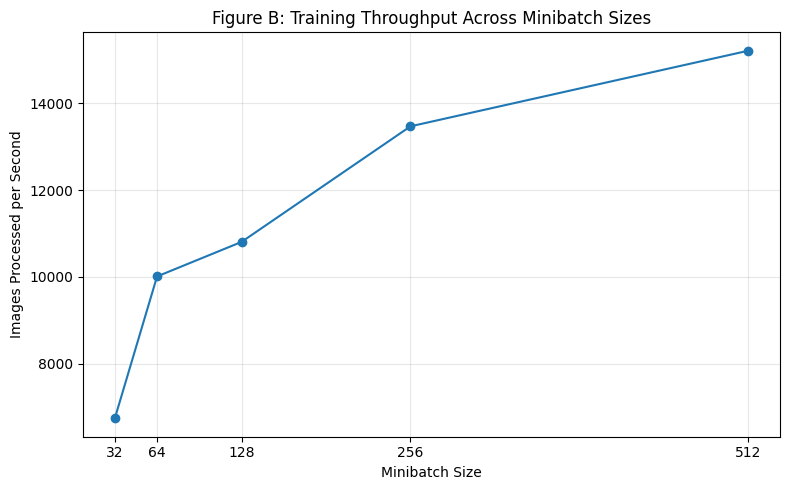

In [96]:
plt.figure(figsize=(8, 5))

plt.plot(
  comparison_summary["Batch Size"],
  comparison_summary["Throughput (images/s)"],
  marker="o"
)

plt.title("Figure B: Training Throughput Across Minibatch Sizes")
plt.xlabel("Minibatch Size")
plt.ylabel("Images Processed per Second")
plt.xticks(batch_sizes)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Overall, this experiment demonstrates a tradeoff between model performance and computational efficiency when changing the minibatch size. Smaller minibatches achieved higher validation accuracy over the three epochs, while larger minibatches reduced training time and increased throughput at the cost of greater GPU memory consumption. Although larger minibatches processed training images more efficiently, they also performed fewer SGD updates per epoch, which may have contributed to their lower classification accuracy under the fixed learning rate.

These findings suggest that increasing the minibatch size alone does not necessarily improve the overall training process. Therefore, in the next experiment, I will investigate whether adjusting the learning rate alongside the minibatch size can improve the convergence of larger minibatches while retaining their computational advantages.

#### Experiment 2: Linear Learning-Rate Scaling
Moving onto the next experiment, let's investigate scaling up the learning rate, where instead of keeping it fixed, it grows proportionally to the minibatch size. Since the larger minibatches performed fewer SGD updates per epoch, it in turn achieved lower validation accuracy after three epochs. A technique to help resolve this is the **linear learning-rate scaling rule**. In short, if larger minibatches perform fewer parameter updates, then increasing the learning rate may help compensate for the reduction. This however may be at the cost of optimization, so improved accuracy is not guaranteed. 

With that being said, let's do this experiment.

In [97]:
# Compare minibatch sizes using linear learning-rate scaling
REFERENCE_BATCH_SIZE = 128
REFERENCE_LEARNING_RATE = 0.01

scaled_results = []

for batch_size in batch_sizes:
  scaled_lr = (
    REFERENCE_LEARNING_RATE
    * batch_size / REFERENCE_BATCH_SIZE
  )

  print(f"Training B = {batch_size}, LR = {scaled_lr:.4f}")

  if batch_size == REFERENCE_BATCH_SIZE:
    history = baseline_history.copy()
  else:
    history = run_experiment(
      batch_size=batch_size,
      learning_rate=scaled_lr,
      epochs=3,
      seed=SEED
    )

  scaled_results.append(history)

scaled_history = pd.concat(
  scaled_results,
  ignore_index=True
)

print("Learning-rate scaling experiment completed.")

Training B = 32, LR = 0.0025
Training B = 64, LR = 0.0050
Training B = 128, LR = 0.0100
Training B = 256, LR = 0.0200
Training B = 512, LR = 0.0400
Learning-rate scaling experiment completed.


In [98]:
# Summarize linear learning-rate scaling results
scaled_summary = (
  scaled_history
  .groupby("Batch Size")
  .agg({
    "Learning Rate": "first",
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

display(scaled_summary.round(4))

,Batch Size,Learning Rate,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,32,0.0025,0.2099,0.2253,3.3170,3.2189,5.8874,6794.2177,42.9619
1,64,0.0050,0.2150,0.2168,3.2887,3.2525,3.9967,10010.4302,64.7241
2,128,0.0100,0.2163,0.2121,3.2841,3.2657,3.7029,10806.1844,108.6240
3,256,0.0200,0.2113,0.2020,3.3063,3.3105,2.8889,13854.4334,196.1738
4,512,0.0400,0.2023,0.1985,3.3525,3.3744,2.7024,14809.8405,690.3442


From the results, we can observe that adjusting the learning rate proportionally to the minibatch size had different effects depending on the size of the minibatch. For smaller minibatches, reducing the learning rate generally resulted in lower validation accuracy compared to the fixed learning-rate experiment. For example, at a batch size of 32, validation accuracy decreased from 27.40% to 22.50%, suggesting that the smaller learning rate may have slowed the optimization process over the three epochs.

On the other hand, larger minibatches benefited from increasing the learning rate. At a batch size of 256, validation accuracy improved from 18.44% to 19.91%, while at a batch size of 512, accuracy improved from 14.01% to 18.85%. This suggests that increasing the learning rate can partially compensate for the smaller number of SGD updates performed by larger minibatches.

In terms of computational efficiency, training time and throughput remained relatively similar to the previous experiment, with larger minibatches continuing to process images more efficiently. GPU memory consumption also remained approximately the same for each corresponding minibatch size, indicating that learning-rate scaling primarily affected optimization behavior rather than the computational requirements of the CNN.

Overall, linear learning-rate scaling improved early training performance for larger minibatches, although it did not completely eliminate the accuracy gap between small and large minibatches.

In [99]:
# Compare final validation accuracy between experiments
lr_comparison = comparison_summary[
  ["Batch Size", "Validation Accuracy"]
].rename(
  columns={"Validation Accuracy": "Fixed LR"}
)

lr_comparison = lr_comparison.merge(
  scaled_summary[["Batch Size", "Validation Accuracy"]].rename(
    columns={"Validation Accuracy": "Scaled LR"}
  ),
  on="Batch Size"
)

lr_comparison["Accuracy Difference"] = (
  lr_comparison["Scaled LR"] - lr_comparison["Fixed LR"]
)

display(lr_comparison.round(4))

,Batch Size,Fixed LR,Scaled LR,Accuracy Difference
0,32,0.2744,0.2253,-0.0491
1,64,0.2503,0.2168,-0.0335
2,128,0.2121,0.2121,0.0000
3,256,0.1838,0.2020,0.0182
4,512,0.1403,0.1985,0.0582


Comparing these results to Experiment 1, we can observe how adjusting the learning rate affects the classification performance of different minibatch sizes. For smaller minibatches, reducing the learning rate resulted in lower validation accuracy. For example, at a batch size of 32, validation accuracy decreased from 27.33% to 22.50%, representing a decrease of 4.83 percentage points. Similarly, at a batch size of 64, validation accuracy decreased by 3.38 percentage points.

On the other hand, larger minibatches benefited from increasing the learning rate. At a batch size of 256, validation accuracy improved from 18.48% to 19.91%, while at a batch size of 512, accuracy improved from 14.02% to 18.85%, an increase of 4.83 percentage points. Meanwhile, both experiments produced the same validation accuracy of 21.13% at a batch size of 128, since this was our reference minibatch size and learning rate.

These differences suggest that linear learning-rate scaling can help improve early training performance for larger minibatches, although reducing the learning rate for smaller minibatches appears to have the opposite effect. To better visualize this relationship, the following graph compares the final validation accuracy of the fixed and scaled learning-rate approaches across all five minibatch sizes.

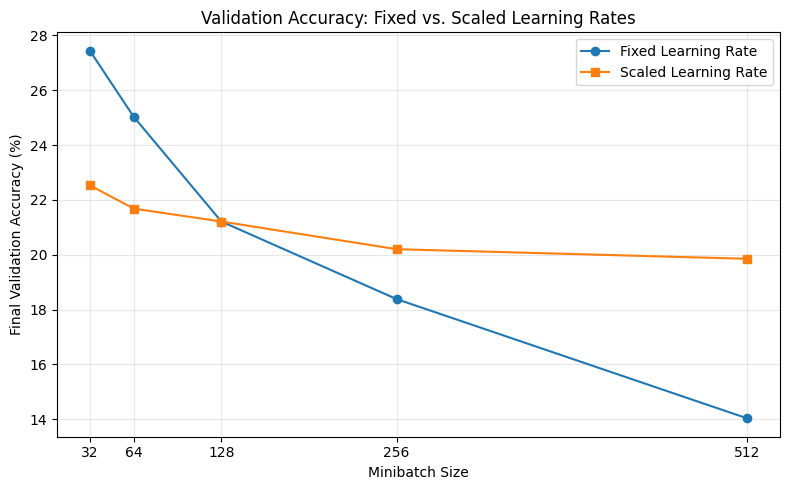

In [100]:
plt.figure(figsize=(8, 5))

plt.plot(
  lr_comparison["Batch Size"],
  lr_comparison["Fixed LR"] * 100,
  marker="o",
  label="Fixed Learning Rate"
)

plt.plot(
  lr_comparison["Batch Size"],
  lr_comparison["Scaled LR"] * 100,
  marker="s",
  label="Scaled Learning Rate"
)

plt.title("Validation Accuracy: Fixed vs. Scaled Learning Rates")
plt.xlabel("Minibatch Size")
plt.ylabel("Final Validation Accuracy (%)")
plt.xticks(batch_sizes)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

Overall, Experiment 2 demonstrates that adjusting the learning rate proportionally to the minibatch size can partially improve the convergence of larger minibatches without sacrificing their computational advantages. However, increasing the learning rate immediately at the beginning of training may not always be the most effective approach, particularly when using larger learning rates that could introduce instability during optimization.

#### Experiment 3: Gradual Learning-rate Warmup
This leads us to our final experiment, where we will investigate gradual learning-rate warmup. Rather than starting training with the full scaled learning rate, we will gradually increase it during the initial training steps. The goal is to determine whether this approach can provide a more stable optimization process and improve the performance of larger minibatches compared to applying linear learning-rate scaling alone.

For this experiment, we'll use a one epoch linear warmup, followed by the full scaled learning rate for the remaining two epochs.

In [101]:
def train_one_epoch_warmup(
  model, loader, optimizer, criterion, device,
  target_lr, warmup_steps, global_step
):
  model.train()

  total_loss = 0.0
  correct = 0
  total = 0

  for images, labels in loader:
    images = images.to(device, non_blocking=True)
    labels = labels.to(device, non_blocking=True)

    global_step += 1

    current_lr = target_lr * min(
      global_step / warmup_steps, 1.0
    )

    for group in optimizer.param_groups:
      group["lr"] = current_lr

    optimizer.zero_grad(set_to_none=True)

    outputs = model(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer.step()

    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += batch_size

  return total_loss / total, correct / total, global_step

def run_warmup_experiment(batch_size, epochs=3, seed=42):
  torch.manual_seed(seed)

  if device.type == "cuda":
    torch.cuda.manual_seed_all(seed)

  train_loader, val_loader = create_dataloaders(batch_size, seed=seed)

  target_lr = 0.01 * batch_size / 128
  warmup_steps = len(train_loader)
  global_step = 0

  model = CIFAR100CNN()
  initialize_model(model)
  model = model.to(device)

  criterion = nn.CrossEntropyLoss()

  optimizer = torch.optim.SGD(
    model.parameters(),
    lr=target_lr,
    momentum=0.9
  )

  history = []

  for epoch in range(1, epochs + 1):
    if device.type == "cuda":
      torch.cuda.synchronize()
      torch.cuda.reset_peak_memory_stats(device)

    start = time.perf_counter()

    train_loss, train_acc, global_step = train_one_epoch_warmup(
      model,
      train_loader,
      optimizer,
      criterion,
      device,
      target_lr,
      warmup_steps,
      global_step
    )

    if device.type == "cuda":
      torch.cuda.synchronize()
      peak_memory = torch.cuda.max_memory_allocated(device) / (1024 ** 2)
    else:
      peak_memory = None

    train_time = time.perf_counter() - start

    val_loss, val_acc = evaluate(
      model, val_loader, criterion, device
    )

    history.append({
      "Epoch": epoch,
      "Batch Size": batch_size,
      "Learning Rate": target_lr,
      "Training Loss": train_loss,
      "Training Accuracy": train_acc,
      "Validation Loss": val_loss,
      "Validation Accuracy": val_acc,
      "Training Time (s)": train_time,
      "Throughput (images/s)": len(train_dataset) / train_time,
      "Peak GPU Memory (MiB)": peak_memory
    })

  return pd.DataFrame(history)

In [102]:
# Compare gradual warmup for larger minibatches
warmup_batch_sizes = [256, 512]

warmup_results = []

for batch_size in warmup_batch_sizes:
  print(f"Training with warmup: B = {batch_size}")

  history = run_warmup_experiment(
    batch_size=batch_size,
    epochs=3,
    seed=SEED
  )

  warmup_results.append(history)

warmup_history = pd.concat(
  warmup_results,
  ignore_index=True
)

print("Gradual warmup experiment completed.")

Training with warmup: B = 256
Training with warmup: B = 512
Gradual warmup experiment completed.


In [103]:
warmup_summary = (
  warmup_history
  .groupby("Batch Size")
  .agg({
    "Learning Rate": "first",
    "Training Accuracy": "last",
    "Validation Accuracy": "last",
    "Training Loss": "last",
    "Validation Loss": "last",
    "Training Time (s)": "mean",
    "Throughput (images/s)": "mean",
    "Peak GPU Memory (MiB)": "max"
  })
  .reset_index()
)

display(warmup_summary.round(4))

,Batch Size,Learning Rate,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss,Training Time (s),Throughput (images/s),Peak GPU Memory (MiB)
0,256,0.02,0.1976,0.1880,3.3913,3.3800,2.8407,14083.7584,196.1738
1,512,0.04,0.1913,0.1996,3.4227,3.4005,2.6828,14910.9677,690.3442


From the results, we can observe that gradual warmup produced different outcomes for the two minibatch sizes. At a batch size of 256, the CNN achieved a validation accuracy of 18.80%, while at a batch size of 512, validation accuracy reached 19.96%. Interestingly, the larger minibatch achieved slightly higher validation accuracy, despite performing fewer SGD updates per epoch.

In terms of computational performance, both configurations maintained high throughput, processing approximately 14,084 and 14,911 images per second, respectively. GPU memory consumption also remained consistent with the earlier experiments, suggesting that introducing warmup did not substantially change the computational requirements of training.

However, these results alone do not establish whether gradual warmup is more effective than linear learning-rate scaling. To investigate this further, the following comparison examines the validation accuracy obtained using fixed learning rates, linear scaling, and gradual warmup.

In [104]:
warmup_comparison = (
  comparison_summary[
    ["Batch Size", "Validation Accuracy"]
  ]
  .rename(columns={
    "Validation Accuracy": "Fixed LR"
  })
  .merge(
    scaled_summary[
      ["Batch Size", "Validation Accuracy"]
    ].rename(columns={
      "Validation Accuracy": "Scaled LR"
    }),
    on="Batch Size"
  )
  .merge(
    warmup_summary[
      ["Batch Size", "Validation Accuracy"]
    ].rename(columns={
      "Validation Accuracy": "Warmup"
    }),
    on="Batch Size"
  )
)

display(
  warmup_comparison[
    warmup_comparison["Batch Size"].isin(warmup_batch_sizes)
  ].round(4)
)

,Batch Size,Fixed LR,Scaled LR,Warmup
0,256,0.1838,0.2020,0.1880
1,512,0.1403,0.1985,0.1996


Comparing the results of all three experiments, we can observe how different learning-rate strategies affect the classification performance of larger minibatches. At a batch size of 256, the fixed learning rate produced a validation accuracy of 18.38%, while linear learning-rate scaling improved it to 20.20%. However, introducing gradual warmup resulted in a slightly lower accuracy of 18.80%, suggesting that warmup did not provide an additional improvement for this configuration.

On the other hand, the results were different for a batch size of 512. The fixed learning rate achieved only 14.03% validation accuracy, while linear scaling increased it to 19.85%. Gradual warmup produced a slightly higher accuracy of 19.96%, representing an improvement of 0.11 percentage points over linear scaling alone. Although this improvement was relatively small, it suggests that warmup may provide some additional benefit when using larger minibatches and learning rates.

Overall, these comparisons show that linear learning-rate scaling provided a more substantial improvement over the fixed learning rate, while the effects of gradual warmup were less consistent. To better illustrate these differences, the following bar chart compares the final validation accuracy of all three approaches for minibatch sizes of 256 and 512.

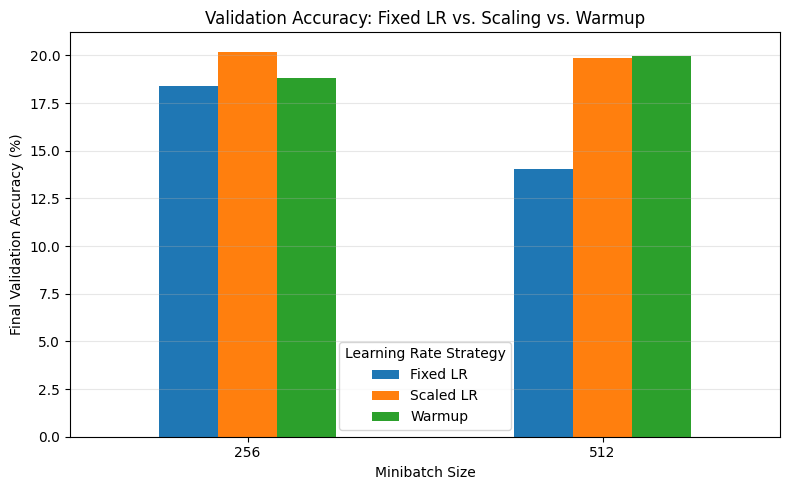

In [105]:
warmup_plot = warmup_comparison[
  warmup_comparison["Batch Size"].isin(warmup_batch_sizes)
].set_index("Batch Size")

ax = (
  warmup_plot[["Fixed LR", "Scaled LR", "Warmup"]] * 100
).plot(
  kind="bar",
  figsize=(8, 5),
  rot=0
)

ax.set_title("Validation Accuracy: Fixed LR vs. Scaling vs. Warmup")
ax.set_xlabel("Minibatch Size")
ax.set_ylabel("Final Validation Accuracy (%)")
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Learning Rate Strategy")

plt.tight_layout()
plt.show()

#### Final Conclusions, Thoughts, and Limitations
Throughout this report, I investigated how minibatch size and learning-rate strategies affect the training performance and computational efficiency of a convolutional neural network using the CIFAR-100 dataset. The experiments focused on three approaches: comparing different minibatch sizes under a fixed learning rate, applying linear learning-rate scaling, and introducing gradual learning-rate warmup.

From Experiment 1, we observed that smaller minibatches generally achieved higher classification accuracy, while larger minibatches demonstrated better computational efficiency. In particular, a minibatch size of 32 achieved the highest validation accuracy, while a minibatch size of 512 achieved the highest training throughput. This highlighted an important tradeoff in SGD: increasing the minibatch size allows more images to be processed simultaneously, but also reduces the number of parameter updates performed during each epoch.

Experiment 2 investigated whether adjusting the learning rate proportionally to the minibatch size could improve the performance of larger minibatches. The results showed that linear learning-rate scaling improved validation accuracy for minibatch sizes of 256 and 512 compared to using a fixed learning rate. However, reducing the learning rate for smaller minibatches resulted in lower accuracy over the same three-epoch training period. These findings suggest that the choice of learning rate plays an important role in determining how effectively different minibatch sizes learn.

Finally, Experiment 3 introduced gradual learning-rate warmup for the two largest minibatches. The results were mixed, with warmup performing worse than linear scaling alone at a batch size of 256, but achieving a slightly higher validation accuracy at a batch size of 512. This suggests that warmup may provide additional benefits in certain configurations, although its effectiveness was not consistent across the two minibatch sizes tested.

Overall, the experiments demonstrate that larger minibatches do not necessarily lead to better model performance, even when they improve computational efficiency. However, adjusting the learning-rate strategy can help recover some of the classification performance lost when increasing the minibatch size. The results also emphasize that training efficiency should not be evaluated solely through throughput or training time, but should also consider the model's learning progress and accuracy.

While the experiments provided useful observations about large-minibatch SGD, there are several limitations worth considering.
- Limited training duration: Each CNN was trained for only three epochs. Although this allowed us to compare multiple configurations efficiently, the models had not necessarily reached convergence. Consequently, the results primarily describe early training behavior rather than their best achievable classification performance.
- Fixed number of epochs: All configurations processed the same number of training images, but smaller minibatches performed substantially more SGD updates. Therefore, differences in validation accuracy cannot be attributed exclusively to minibatch size, since the number of parameter updates also varied.
- Simplified CNN architecture: The experiments used a relatively small CNN with three convolutional blocks rather than a more advanced architecture. While this kept the experiments computationally manageable, the results may differ for deeper neural networks or models with substantially more parameters.
- Limited learning-rate schedules: Linear scaling was based on a reference minibatch size of 128, while gradual warmup was applied for one complete epoch. Other reference learning rates, warmup durations, and scheduling methods could produce different results.
- Single experimental runs: Each configuration was evaluated using one training run with a fixed random seed. Although this helped maintain consistency, the experiments did not measure variability across multiple independent runs. Small differences in accuracy, particularly the improvement observed with warmup at a batch size of 512, should therefore be interpreted cautiously.

Overall as a personal reflection, these experiments helped me see behind the computational efficiency of CNNs, as while the other part of the report explores more on the architecture, this one explores how the specific hyperparameters can affect the performance of the model. And so walking out of both experiments, they all helped me in understanding how CNNs work generally.

For reference, this part of the report is based on the 2017 paper [Accurate, Large Minibatch SGD: Training ImageNet in 1 Hour.](https://arxiv.org/abs/1706.02677) by Priya Goyal et al. 